# 11 · Curvas ROC y reporte de clasificación del modelo de SMM — morbilidad materna severa (M2), MIMIC-IV

| Campo | Contenido |
|---|---|
| Secuencia de notebooks | 01 → 02 → 03: E6 · E7 · P3 · R1 · E8 → … → 10: P4 · E10 · E11 → **11: figuras de E8 (complemento)** |
| Qué hace | Vuelve a correr solo el análisis principal del notebook 03 (mismo código, semillas y particiones agrupadas por paciente, sin el bootstrap) para dibujar la curva ROC de cada algoritmo en su propia gráfica y, para el modelo final (XGBoost, algoritmo principal), el reporte de clasificación junto a la matriz de confusión |
| Por qué un notebook aparte | Los notebooks 01 a 10 se corrieron para el artículo y tardan horas; no se modifican. Este notebook solo agrega figuras |
| Etapas | E8 (figuras de la etapa de modelado y validación); no cambia ninguna puerta ni clasificación |
| Entradas | Base local PostgreSQL de MIMIC-IV (tablas de `sql/`), como el notebook 03 |
| Salidas | `figures/11_roc_learners_es.png`, `figures/11_report_confusion_xgb_es.png` y `data/outputs_11_roc_confusion_main.txt` (solo agregados) |
| Uso de los datos | Solo se muestran y guardan resultados agregados; nada a nivel de paciente |
| Tiempo | Unos 25 minutos (el análisis principal del notebook 03 sin el bootstrap) |
| Versión en inglés | `11_roc_confusion_main_smm.ipynb` (mismo código) |

> **Verificación.** El AUROC de cada algoritmo, promedio de las 3 repeticiones, debe ser igual al de `data/outputs_main.txt` (artículo). Si difiere, las predicciones no son las del artículo y las figuras no se deben usar.

## E1 · Configuración, datos y puerta P1 (celdas copiadas del notebook 03)

Misma configuración, semilla, conexión, tabla de predictores y conteos de referencia del notebook 03.

In [1]:
import os, sys, time, math, warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# notebooks/ -> project root is one level up
sys.path.append(os.path.abspath(os.path.join("..")))
import libraries.database as db_lib
engine = db_lib.get_connect_database()

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

# ----------------------------------------------------------------------------- settings
QUICK        = False        # True = smoke test (small forests, 1 repeat, B = 50). Never report QUICK numbers.
SEED         = 20260101
OUTER_FOLDS  = 5
N_REPEATS    = 3            # repeats of the outer grouped CV (development instability)
INNER_FOLDS  = 3
BOOT         = 1000         # cluster bootstrap replicates for the main analysis
BOOT_SENS    = 300          # replicates for the sensitivity analyses
N_JOBS       = -1
N_TREES      = 300
XGB_TREES    = 200
APPLY_LIMITS = True         # set values outside the plausibility limits of the dictionary to missing
CAT_COLS     = ["ethnicity", "insurance", "language", "admission_type", "admission_location"]
DCA_T        = [0.005, 0.01, 0.02, 0.03, 0.05, 0.10, 0.15, 0.20]
EXPECTED     = {"eligible_deliveries": 19383, "smm": 445, "deaths": 3}   # from the audit counts (Q-F / Q-G)

if QUICK:
    OUTER_FOLDS, N_REPEATS, BOOT, BOOT_SENS = 3, 1, 50, 30
    N_TREES, XGB_TREES = 60, 50
print(f"QUICK={QUICK}  outer={OUTER_FOLDS}x{N_REPEATS}  inner={INNER_FOLDS}  B={BOOT}  trees={N_TREES}")

# ----------------------------------------------------------------------------- language and presentation
# Language of the outputs: "es" in the Spanish notebook, "en" in the English one (the only line that differs).
# Nothing below changes a computation: it only decides how tables and messages are shown. The English aggregate
# reports data/outputs_*.txt are written exactly as before (the article cites them); the Spanish notebook also
# writes a translated copy, data/outputs_*_es.txt.
LANG = "es"
import builtins, contextlib, importlib, io, html as _html
import numpy as np
import libraries.i18n_es, libraries.i18n          # reloaded so that a running kernel picks up dictionary changes
importlib.reload(libraries.i18n_es); importlib.reload(libraries.i18n)
from libraries.i18n import translate
pd.set_option("display.max_colwidth", None)
def _tr(s, lang=None):
    """Translate one line keeping its indentation and trailing spaces."""
    lang = lang or LANG
    if lang != "es" or not isinstance(s, str):
        return s
    out = []
    for ln in s.split("\n"):
        core = ln.strip()
        if not core:
            out.append(ln); continue
        i = ln.index(core)
        out.append(ln[:i] + translate(core, "es") + ln[i + len(core):])
    return "\n".join(out)

_REC = None          # while emit() runs: the blocks of the English report, [("text", line) | ("table", frame, index)]

def print(*args, sep=" ", end="\n", file=None, flush=False):
    """Inside emit() the English text goes to the report unchanged; outside it, messages follow LANG."""
    if _REC is not None and file is None:
        _REC.append(("text", sep.join(str(a) for a in args)))
        return builtins.print(*args, sep=sep, end=end, flush=flush)
    if LANG == "es":
        args = [_tr(a, "es") for a in args]
    return builtins.print(*args, sep=sep, end=end, file=file, flush=flush)

def _cell_fmt(v):
    # Display format of a cell: thousands separator for counts, 4 significant digits for small values.
    if isinstance(v, (bool, np.bool_)) or v is None or (isinstance(v, float) and np.isnan(v)):
        return v
    if isinstance(v, (int, np.integer)):
        return f"{int(v):,}"
    if isinstance(v, (float, np.floating)):
        if float(v).is_integer() and abs(v) >= 1000:
            return f"{int(v):,}"
        return f"{v:.4g}" if abs(v) < 1 else f"{v:,.4f}".rstrip("0").rstrip(".")
    return v

def _html_table(df, index):
    df = df.astype(object)
    df = df.map(_cell_fmt) if hasattr(df, "map") else df.applymap(_cell_fmt)
    return f"<div style='max-height:420px; overflow:auto'>{df.to_html(index=index, na_rep='', border=0)}</div>"

def _in_notebook():
    try:
        from IPython import get_ipython
        return get_ipython() is not None
    except ImportError:
        return False

def table(df, index=False, title=None):
    """Show a table. Inside emit() it also prints the English text of the report (df.to_string)."""
    if isinstance(df, pd.Series):
        df = df.to_frame()
        index = True
    if _REC is not None:
        _REC.append(("table", df, index))
        return builtins.print(df.to_string(index=index))
    if not _in_notebook():
        return builtins.print(translate(df, LANG).to_string(index=index))
    from IPython.display import HTML, display as _display
    head = f"<p style='margin:14px 0 4px 0'><b>{_html.escape(_tr(title))}</b></p>" if title else ""
    _display(HTML(head + _html_table(translate(df, LANG), index)))

def _blocks_html(blocks):
    """Report blocks as HTML: a text line right before a table is its title; rules of '=' are dropped."""
    out, pending = [], []
    def flush_text():
        for ln in pending:
            if ln.strip():
                out.append(f"<div style='white-space:pre-wrap; font-family:monospace; margin:2px 0'>{_html.escape(_tr(ln.rstrip()))}</div>")
        pending.clear()
    for b in blocks:
        if b[0] == "text":
            pending.extend(l for l in b[1].split("\n") if not set(l.strip()) <= {"="} or not l.strip())
        else:
            title = None
            while pending and not pending[-1].strip():
                pending.pop()
            if pending:
                title = pending.pop().strip()
            flush_text()
            if title:
                out.append(f"<p style='margin:14px 0 4px 0'><b>{_html.escape(_tr(title))}</b></p>")
            out.append(_html_table(translate(b[1], LANG), b[2]))
    flush_text()
    return "\n".join(out)

def _blocks_text_es(blocks):
    """Spanish copy of a report (data/outputs_*_es.txt)."""
    lines = []
    for b in blocks:
        if b[0] == "text":
            lines.extend(_tr(l, "es") for l in b[1].split("\n"))
        else:
            lines.extend(translate(b[1], "es").to_string(index=b[2]).split("\n"))
    return "\n".join(lines) + "\n"

def _emit_to(path, fn, show=True):
    """Run fn, write its English text to `path` exactly as printed and, from the Spanish notebook, a translated copy
    (*_es.txt); show the report as tables."""
    global _REC
    buf = io.StringIO()
    _REC = []
    try:
        with contextlib.redirect_stdout(buf):
            fn()
    finally:
        blocks, _REC = _REC, None
    text = buf.getvalue()
    with open(path, "w", encoding="utf-8") as fh:
        fh.write(text)
    if show:
        show_report(blocks)
    if LANG == "es":
        with open(path.replace(".txt", "_es.txt"), "w", encoding="utf-8") as fh:
            fh.write(_blocks_text_es(blocks))
    return text

def show_report(blocks):
    if _in_notebook():
        from IPython.display import HTML, display as _display
        _display(HTML(_blocks_html(blocks)))
    else:
        for b in blocks:
            builtins.print(_tr(b[1]) if b[0] == "text" else translate(b[1], LANG).to_string(index=b[2]))

def notebook_summary(rows, title="Notebook summary"):
    """Summary of the notebook (as in the neonatal repository): one value per row; a value that cannot be computed
    (for example, an analysis that was not run in this session) is shown as n/a."""
    out = {}
    for label, fn in rows:
        try:
            v = fn() if callable(fn) else fn
        except Exception:
            v = "n/a"
        out[label] = v
    table(pd.Series(out, name="value").to_frame(), index=True, title=title)

def _m(res, model, met, d=3):
    """Point value of a metric with its 95% bootstrap interval, from a result with "point" and "boot"."""
    v = f"{res['point'][(model, met)]:.{d}f}"
    b = res.get("boot") or {}
    a = b.get((model, met)) if isinstance(b, dict) else None
    if a is not None and len(a) >= 20:
        lo, hi = np.nanpercentile(a, [2.5, 97.5])
        v += f" ({lo:.{d}f}-{hi:.{d}f})"
    return v

def _cv_auroc(res, model):
    """AUROC averaged over the repeats of a cross-validation result that only keeps out-of-fold predictions."""
    from sklearn.metrics import roc_auc_score
    y = res["y"]
    return float(np.mean([roc_auc_score(y, res["preds"][model][r]) for r in range(len(res["preds"][model]))]))


QUICK=False  outer=5x3  inner=3  B=1000  trees=300


In [2]:
df = pd.read_sql("SELECT * FROM mimiciv.predictors_24h_v2", engine)
dic = pd.read_sql("""SELECT variable, model_role_final, missingness_indicator_main, plausible_low, plausible_high,
                            n_eligible_delivery, coverage_pct
                     FROM mimiciv.predictor_dictionary_final_v2""", engine)

for c in ["eligible_24h", "icu_in_24h", "is_delivery_v2", "smm_any", "died_same_admission"]:
    df[c] = df[c].fillna(False).astype(bool)
df["admittime"] = pd.to_datetime(df["admittime"])

VAR_MAIN = dic.loc[dic.model_role_final == "main model", "variable"].tolist()
VAR_ICU  = dic.loc[dic.model_role_final == "ICU sensitivity only", "variable"].tolist()
VAR_LAB  = dic.loc[dic.model_role_final.str.startswith("laboratory sensitivity"), "variable"].tolist()
IND_MAIN = dic.loc[dic.missingness_indicator_main.fillna(False).astype(bool), "variable"].tolist()

print("Dictionary roles ->", {"main": VAR_MAIN, "ICU only": len(VAR_ICU), "lab sensitivity": len(VAR_LAB),
                              "missingness indicator in main model": IND_MAIN})

# Plausibility limits (proposals pending clinical confirmation): out-of-range values become missing
if APPLY_LIMITS:
    n_set = {}
    for _, r in dic.dropna(subset=["plausible_low", "plausible_high"]).iterrows():
        v = r["variable"]
        if v in df.columns:
            bad = (df[v] < r["plausible_low"]) | (df[v] > r["plausible_high"])
            n_set[v] = int(bad.sum())
            df.loc[bad, v] = np.nan
    print("Values set to missing by plausibility limits (count per variable):", n_set)

# Missingness indicators (computed row by row from the raw value: no information crosses patients)
for v in set(IND_MAIN + VAR_LAB + VAR_ICU):
    df[f"{v}_missing"] = df[v].isna().astype(int)
df["icu_in_24h_bin"] = df["icu_in_24h"].astype(int)
df["y"] = df["smm_any"].astype(int)

# Audit checks against the counts already certified (aggregate only)
elig = df[df.eligible_24h & df.is_delivery_v2]
chk = {"eligible_deliveries": len(elig), "smm": int(elig.smm_any.sum()), "deaths": int(elig.died_same_admission.sum())}
for k, v in chk.items():
    print(f"{k}: {v}  (expected {EXPECTED[k]})  [{'OK' if v == EXPECTED[k] else 'CHECK: differs from the audit counts'}]")
print("Eligible any obstetric admissions:", int(df.eligible_24h.sum()),
      "| SMM:", int(df[df.eligible_24h].smm_any.sum()), "| deaths:", int(df[df.eligible_24h].died_same_admission.sum()))

Roles del diccionario -> {'main': ['hemoglobin', 'creatinine'], 'ICU only': 14, 'lab sensitivity': 11, 'missingness indicator in main model': ['creatinine']}
Valores llevados a faltante por los límites de plausibilidad (conteo por variable): {'hemoglobin': 0, 'hematocrit': 0, 'creatinine': 1}
partos elegibles: 19383  (esperado 19383)  [OK]
SMM: 445  (esperado 445)  [OK]
muertes: 3  (esperado 3)  [OK]
Admisiones obstétricas elegibles de cualquier tipo: 23625 | SMM: 814 | deaths: 5


In [3]:
# Gate G1 decision: the loaded data must reproduce the reference counts frozen at the count audit (aggregates only)
g1 = pd.DataFrame([{"count": k, "loaded": v, "expected": EXPECTED[k],
                    "result": "reproduced" if v == EXPECTED[k] else "DIFFERS"} for k, v in chk.items()])
table(g1, title="Gate G1: reference counts")
table(pd.Series({"G1 decision": "passes: continue to the analyses" if (g1["result"] == "reproduced").all()
                 else "does NOT pass: review the tables of sql/ before fitting any model"}, name="decision"),
      title="Gate G1 decision")

conteo,cargado,esperado,resultado
partos elegibles,"19,383","19,383",reproducido
SMM,445,445,reproducido
muertes,3,3,reproducido


,decisión
decisión P1,pasa: se sigue con los análisis


## E6 · E8 · Especificación del análisis y funciones de modelado (copiadas del notebook 03)

Preprocesamiento, algoritmos, ajuste anidado agrupado por paciente, ensamble apilado y calibración de Platt, exactamente como en el artículo.

In [4]:
def make_spec(name):
    d = df[df.eligible_24h].copy()
    num = ["age_at_admission"] + VAR_MAIN
    binc = [f"{v}_missing" for v in IND_MAIN]
    label = "y"
    if name in ("main", "labs_extended", "icu_vars", "label_ge2", "no_icu_24h", "icd10_only"):
        d = d[d.is_delivery_v2]
        if name == "no_icu_24h":
            d = d[~d.icu_in_24h]
    elif name == "first_admission":
        first = df[df.is_delivery_v2].sort_values(["subject_id", "admittime", "hadm_id"]).drop_duplicates("subject_id")
        d = d[d.hadm_id.isin(first.hadm_id)]
    elif name == "any_obstetric":
        pass
    else:
        raise ValueError(name)
    if name == "icd10_only":
        ver = pd.read_sql("SELECT hadm_id, has_icd9_dx, has_icd10_dx FROM mimiciv.cohort_obstetric_v2", engine)
        ver["has_icd9_dx"] = ver["has_icd9_dx"].fillna(False).astype(bool)
        ver["has_icd10_dx"] = ver["has_icd10_dx"].fillna(False).astype(bool)
        keep = ver.loc[ver.has_icd10_dx & ~ver.has_icd9_dx, "hadm_id"]
        d = d[d.hadm_id.isin(keep)]
    if name == "labs_extended":
        num = num + VAR_LAB
        binc = binc + [f"{v}_missing" for v in VAR_LAB if f"{v}_missing" not in binc]
    if name == "icu_vars":
        num = num + VAR_ICU
        binc = binc + [f"{v}_missing" for v in VAR_ICU] + ["icu_in_24h_bin"]
    if name == "label_ge2":
        g2 = pd.read_sql("SELECT hadm_id, smm_ge2 FROM mimiciv.cohort_obstetric_v2", engine)
        g2["smm_ge2"] = g2["smm_ge2"].fillna(False).astype(bool).astype(int)
        d = d.merge(g2, on="hadm_id", how="left")
        d["y_ge2"] = d["smm_ge2"].fillna(0).astype(int)
        label = "y_ge2"
    # drop columns that do not exist or never vary (a constant indicator carries no information)
    num  = [c for c in dict.fromkeys(num) if c in d.columns]
    binc = [c for c in dict.fromkeys(binc) if c in d.columns and d[c].nunique() > 1]
    cat  = [c for c in CAT_COLS if c in d.columns]
    d = d.reset_index(drop=True)
    return dict(name=name, data=d, num=num, bin=binc, cat=cat, label=label)

for nm in ["main", "first_admission", "any_obstetric", "labs_extended", "icu_vars", "no_icu_24h", "icd10_only"]:
    sp = make_spec(nm)
    d = sp["data"]
    print(f"{nm:16s} admissions={len(d):6d}  patients={d.subject_id.nunique():6d}  events={int(d[sp['label']].sum()):4d}  "
          f"numeric={len(sp['num'])}  binary={len(sp['bin'])}  categorical={len(sp['cat'])}")

main: admisiones=19383, pacientes=13710, eventos=445, numéricas=3, binarias=1, categóricas=5
first_admission: admisiones=13701, pacientes=13701, eventos=356, numéricas=3, binarias=1, categóricas=5
any_obstetric: admisiones=23625, pacientes=14602, eventos=814, numéricas=3, binarias=1, categóricas=5
labs_extended: admisiones=19383, pacientes=13710, eventos=445, numéricas=14, binarias=12, categóricas=5
icu_vars: admisiones=19383, pacientes=13710, eventos=445, numéricas=17, binarias=16, categóricas=5
no_icu_24h: admisiones=19268, pacientes=13632, eventos=355, numéricas=3, binarias=1, categóricas=5
icd10_only: admisiones=8864, pacientes=7070, eventos=271, numéricas=3, binarias=1, categóricas=5


In [5]:
def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

def expit(z):
    return 1.0 / (1.0 + np.exp(-z))

class Winsor(BaseEstimator, TransformerMixin):
    """Clip each column to training percentiles (fit on the training data only)."""
    def __init__(self, lo=0.5, hi=99.5):
        self.lo = lo; self.hi = hi
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_ = np.nanpercentile(X, self.lo, axis=0)
        self.hi_ = np.nanpercentile(X, self.hi, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)

def make_prep(num, binc, cat):
    parts = [("num", Pipeline([("w", Winsor()),
                               ("imp", SimpleImputer(strategy="median", keep_empty_features=True)),
                               ("sc", StandardScaler())]), num)]
    if binc:
        parts.append(("bin", "passthrough", binc))
    if cat:
        parts.append(("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                                       ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                            min_frequency=0.01, sparse_output=False))]), cat))
    return ColumnTransformer(parts)

def prep_frame(d, num, binc, cat):
    X = d[num + binc + cat].copy()
    for c in cat:
        X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
    return X

# Small prespecified grids (class weights are options; no resampling)
GRID = {
    # The grids cover values beyond those most often chosen in preliminary runs, so that the selected value
    # is not at the edge of the grid (ET depth, RF depth and XGB depth; class weights remain options).
    "LR":  [dict(C=C, cw=cw) for C in (0.01, 0.1, 1.0) for cw in (None, "balanced")],
    "RF":  [dict(depth=dp, cw=cw) for dp in (2, 4, 8) for cw in (None, "balanced_subsample")],
    "ET":  [dict(depth=dp, cw=cw) for dp in (4, 8, 12) for cw in (None, "balanced_subsample")],
    "XGB": [dict(depth=dp, spw=sp) for dp in (1, 2, 4) for sp in (1, "sqrt")],
}
MODELS = ["LR", "RF", "ET", "XGB", "Stack", "Stack_raw"]
BOOT_MODELS = ["LR", "RF", "ET", "XGB", "Stack"]
PAIRS = [("RF", "LR"), ("ET", "LR"), ("XGB", "LR"), ("Stack", "LR"), ("Stack", "XGB")]

def cfg_str(c):
    return ",".join(f"{k}={v}" for k, v in c.items())

def make_clf(name, cfg, ytr, seed):
    if name == "LR":
        return LogisticRegression(C=cfg["C"], class_weight=cfg["cw"], max_iter=3000)
    if name == "RF":
        return RandomForestClassifier(n_estimators=N_TREES, max_depth=cfg["depth"], min_samples_leaf=20,
                                      class_weight=cfg["cw"], n_jobs=N_JOBS, random_state=seed)
    if name == "ET":
        return ExtraTreesClassifier(n_estimators=N_TREES, max_depth=cfg["depth"], min_samples_leaf=20,
                                    class_weight=cfg["cw"], n_jobs=N_JOBS, random_state=seed)
    if name == "XGB":
        pos = max(int(ytr.sum()), 1); neg = max(len(ytr) - pos, 1)
        spw = math.sqrt(neg / pos) if cfg["spw"] == "sqrt" else 1.0
        return XGBClassifier(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=cfg["depth"], subsample=0.8,
                             colsample_bytree=0.8, min_child_weight=5, scale_pos_weight=spw, eval_metric="logloss",
                             tree_method="hist", n_jobs=N_JOBS if N_JOBS and N_JOBS > 0 else 0, random_state=seed)
    raise ValueError(name)

def fit_predict(name, cfg, prep, Xtr, ytr, Xte, seed):
    pipe = Pipeline([("prep", clone(prep)), ("clf", make_clf(name, cfg, ytr, seed))])
    pipe.fit(Xtr, ytr)
    return pipe.predict_proba(Xte)[:, 1]

def platt(o, t, ytr):
    c = LogisticRegression(penalty=None, max_iter=1000).fit(logit(o).reshape(-1, 1), ytr)
    return c.predict_proba(logit(t).reshape(-1, 1))[:, 1]

def tune_stack_calibrate(Xtr, ytr, gtr, Xte, prep, seed):
    """Inside one outer training set: tune, build out-of-fold predictions, stack, calibrate; score the outer test set."""
    inner = list(StratifiedGroupKFold(INNER_FOLDS, shuffle=True, random_state=seed).split(Xtr, ytr, gtr))
    names = list(GRID)
    chosen, oof, pred_te = {}, {}, {}
    for name in names:
        best = None
        for cfg in GRID[name]:
            o = np.zeros(len(ytr))
            for tr, va in inner:
                o[va] = fit_predict(name, cfg, prep, Xtr.iloc[tr], ytr[tr], Xtr.iloc[va], seed)
            ap = average_precision_score(ytr, o)
            if best is None or ap > best[0]:
                best = (ap, cfg, o)
        chosen[name] = best[1]; oof[name] = best[2]
        pred_te[name] = fit_predict(name, best[1], prep, Xtr, ytr, Xte, seed)
    # explicit stacking: logistic meta-learner on out-of-fold base predictions (C = 0.1 as in the original framework)
    Z_oof = np.column_stack([logit(oof[n]) for n in names])
    Z_te = np.column_stack([logit(pred_te[n]) for n in names])
    meta = LogisticRegression(C=0.1, max_iter=2000).fit(Z_oof, ytr)
    stack_te_raw = meta.predict_proba(Z_te)[:, 1]
    # cross-fitted meta out-of-fold predictions -> calibrator never sees the predictions of its own training rows
    mo = np.zeros(len(ytr))
    for tr, va in StratifiedGroupKFold(INNER_FOLDS, shuffle=True, random_state=seed + 1).split(Z_oof, ytr, gtr):
        m = LogisticRegression(C=0.1, max_iter=2000).fit(Z_oof[tr], ytr[tr])
        mo[va] = m.predict_proba(Z_oof[va])[:, 1]
    out = {n: platt(oof[n], pred_te[n], ytr) for n in names}
    out["Stack"] = platt(mo, stack_te_raw, ytr)
    out["Stack_raw"] = stack_te_raw
    return out, chosen

def run_cv(spec, label=translate("", LANG)):
    d = spec["data"]
    X = prep_frame(d, spec["num"], spec["bin"], spec["cat"])
    y = d[spec["label"]].values.astype(int)
    g = d["subject_id"].values
    prep = make_prep(spec["num"], spec["bin"], spec["cat"])
    n = len(y)
    preds = {m: np.full((N_REPEATS, n), np.nan) for m in MODELS}
    chosen_log = []
    split_log = []
    t0 = time.time(); done = 0; total = N_REPEATS * OUTER_FOLDS
    for r in range(N_REPEATS):
        outer = StratifiedGroupKFold(OUTER_FOLDS, shuffle=True, random_state=SEED + r)
        for k, (tr, te) in enumerate(outer.split(X, y, g)):
            assert len(set(g[tr]) & set(g[te])) == 0, "patient present in training and test"
            split_log.append(dict(repeat=r + 1, fold=k + 1,
                                  train_adm=len(tr), train_pat=len(set(g[tr])), train_events=int(y[tr].sum()),
                                  train_event_pat=len(set(g[tr][y[tr] == 1])),
                                  test_adm=len(te), test_pat=len(set(g[te])), test_events=int(y[te].sum()),
                                  test_event_pat=len(set(g[te][y[te] == 1])), shared_patients=0))
            out, chosen = tune_stack_calibrate(X.iloc[tr], y[tr], g[tr], X.iloc[te], prep, SEED + 100 * r + k)
            for m in MODELS:
                preds[m][r, te] = out[m]
            for nme, cfg in chosen.items():
                chosen_log.append((nme, cfg_str(cfg)))
            done += 1
            if done == 1:
                el = time.time() - t0
                print(f"[{spec['name']}] first outer fold took {el/60:.1f} min -> projected total about {el*total/60:.0f} min")
    print(f"[{spec['name']}] cross-validation finished in {(time.time()-t0)/60:.1f} min; "
          f"every admission scored exactly once per repeat: {bool(np.isfinite(preds['Stack']).all())}")
    return dict(spec=spec, y=y, g=g, preds=preds, chosen=chosen_log, X=X, prep=prep, splits=pd.DataFrame(split_log))

## E8 · Análisis principal — predicciones fuera de muestra y verificación frente al artículo

| Resultado | Qué se hace | En este modelo |
|---|---|---|
| AUROC de cada algoritmo = `outputs_main.txt` | Las figuras muestran los modelos del artículo | Al correr |
| Un valor difiere | No usar las figuras; revisar el entorno (versiones de las librerías) | — |

In [6]:
# Main analysis of notebook 03 without the bootstrap: same specification, folds, seeds and learners.
res_main = run_cv(make_spec("main"))
y_main = res_main["y"].astype(bool)
# Check against the article (data/outputs_main.txt): AUROC of each learner averaged over the repeats
ARTICLE = {"LR": 0.780, "RF": 0.777, "ET": 0.770, "XGB": 0.791, "Stack": 0.789}
auc_mean = {m: float(np.mean([roc_auc_score(y_main, res_main["preds"][m][r]) for r in range(N_REPEATS)])) for m in ARTICLE}
check = pd.DataFrame([{"learner": m, "AUROC article": a, "AUROC this run": round(auc_mean[m], 3),
                       "result": "reproduced" if round(auc_mean[m], 3) == a else "DIFFERS"} for m, a in ARTICLE.items()])
table(check, title="Check: AUROC of each learner (mean of the repeats) against the article")
if QUICK:
    print("QUICK = True: the check is not meaningful; never use these figures")

[main] el primer pliegue externo tardó 1.2 min -> total proyectado de unos 18 min
[main] validación cruzada terminada en 12.0 min; cada admisión evaluada exactamente una vez por repetición: Sí


algoritmo,AUROC del artículo,AUROC de esta corrida,resultado
LR,0.78,0.78,reproducido
RF,0.777,0.777,reproducido
ET,0.77,0.77,reproducido
XGB,0.791,0.791,reproducido
Stack,0.789,0.789,reproducido


## E8 · Figuras — curvas ROC de los algoritmos y reporte de clasificación del modelo final

ROC: predicciones fuera de muestra de la repetición 1, una gráfica por algoritmo. Modelo final: XGBoost (algoritmo principal, decisión del 11/11/2026), reporte de clasificación (precisión, sensibilidad, F1, exactitud, promedio macro) junto a la matriz de confusión con el 10% de mayor riesgo. La exactitud y el F1 se reportan, pero no deciden: con una prevalencia de SMM de 2,3%, no marcar a nadie ya da una exactitud de 0,977.

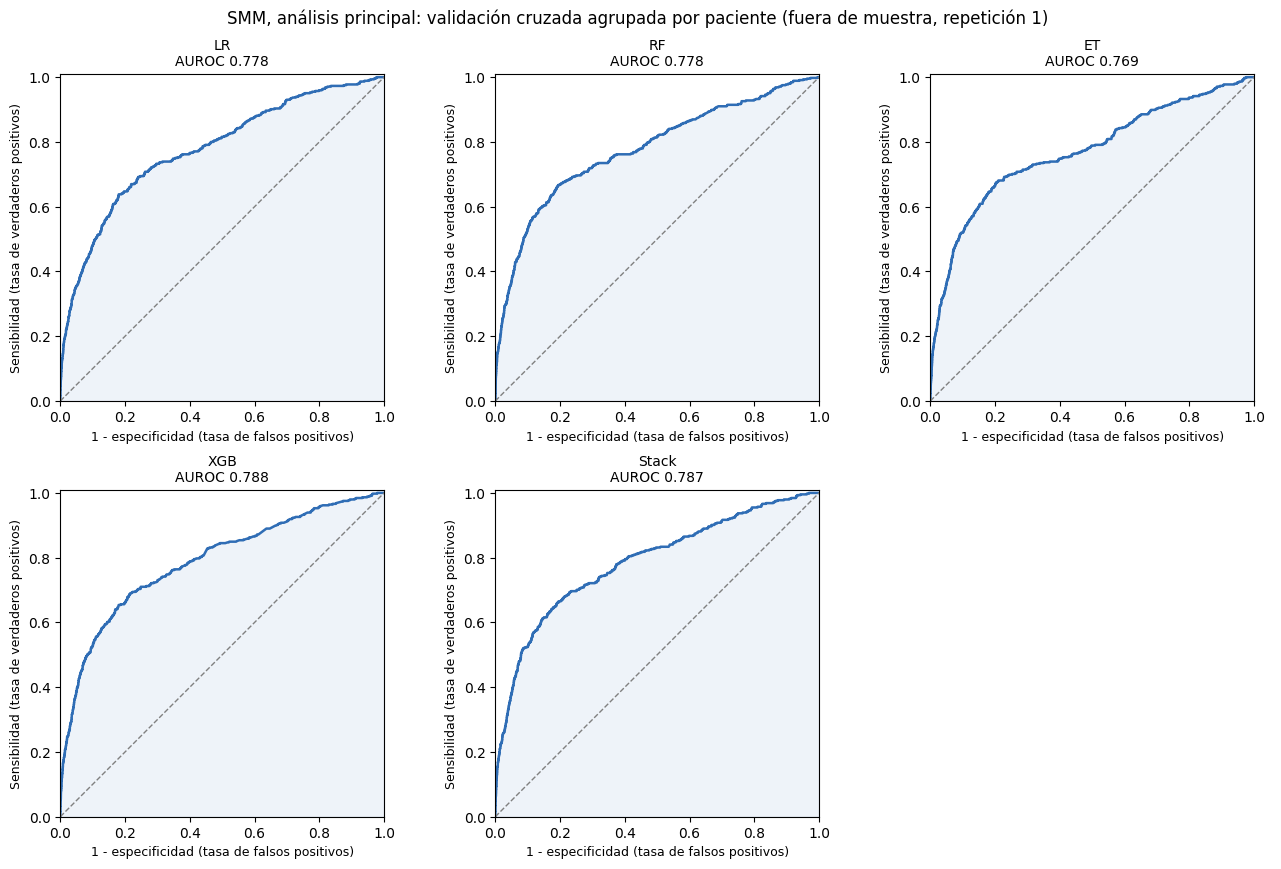

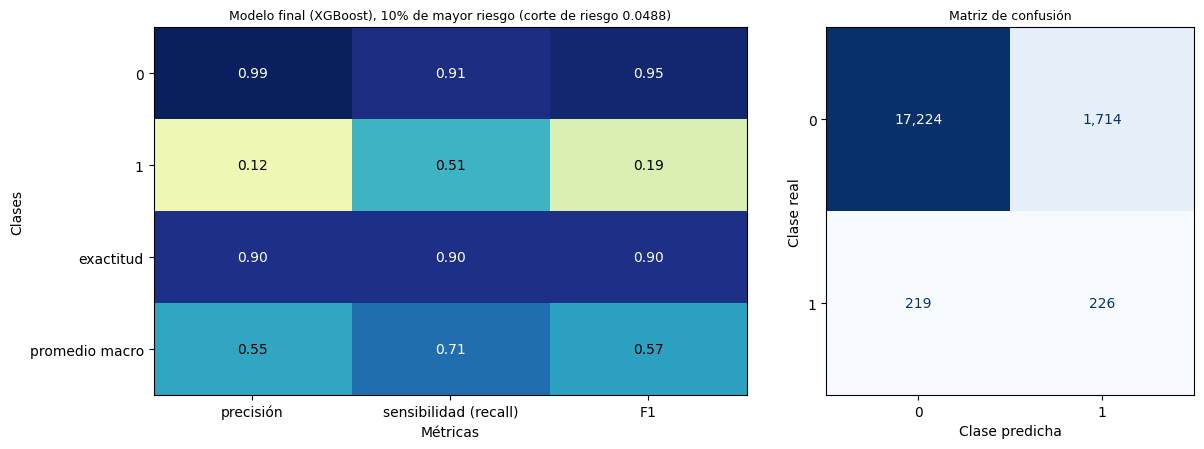

,corte de riesgo,VP,FP,FN,VN,exactitud,F1,sensibilidad,especificidad,VPP,VPN
algoritmo,,,,,,,,,,,
LR,0.0516,203,"1,736",242,"17,202",0.898,0.1703,0.4562,0.9083,0.1047,0.9861
RF,0.0449,226,"1,713",219,"17,225",0.9003,0.1896,0.5079,0.9095,0.1166,0.9875
ET,0.0563,226,"1,713",219,"17,225",0.9003,0.1896,0.5079,0.9095,0.1166,0.9875
XGB,0.0488,226,"1,714",219,"17,224",0.9003,0.1895,0.5079,0.9095,0.1165,0.9874
Stack,0.0499,232,"1,707",213,"17,231",0.9009,0.1946,0.5213,0.9099,0.1196,0.9878


In [7]:
# Figures (repeat 1 of the out-of-fold predictions). No sampling weights: every admission counts once.
import importlib, libraries.figures
importlib.reload(libraries.figures)
from libraries.figures import plot_roc, plot_report_cm, threshold_metrics, cut_top
from pathlib import Path
FIG_DIR = Path("..") / "figures"
LEARNERS = ["LR", "RF", "ET", "XGB", "Stack"]
w_main = np.ones(len(y_main))
plot_roc([(m, y_main, res_main["preds"][m][0]) for m in LEARNERS],
         "SMM, main analysis: patient-grouped cross-validation (out-of-fold, repeat 1)", "11_roc_learners.png", LANG, FIG_DIR)
p_xgb = res_main["preds"]["XGB"][0]
plot_report_cm([("Final model (XGBoost), top 10% of risk", y_main, p_xgb, w_main, cut_top(p_xgb, w_main, 0.10))],
               "11_report_confusion_xgb.png", LANG, FIG_DIR)
thr = pd.DataFrame({m: threshold_metrics(y_main, res_main["preds"][m][0], w_main, cut_top(res_main["preds"][m][0], w_main, 0.10))
                    for m in LEARNERS}).T
thr.index.name = "learner"
thr[["TP", "FP", "FN", "TN"]] = thr[["TP", "FP", "FN", "TN"]].astype(int)

def _report11():
    print("Check: AUROC of each learner (mean of the repeats) against the article")
    table(check)
    print("Threshold metrics at the top 10% of risk (out-of-fold, repeat 1)")
    table(thr, index=True)
_emit_to("../data/outputs_11_roc_confusion_main.txt", _report11, show=False)
table(thr, index=True, title="Threshold metrics at the top 10% of risk (out-of-fold, repeat 1)")

## Resumen del notebook

In [8]:
# Summary of notebook 11
notebook_summary([
    ("admissions / SMM events", lambda: f"{len(y_main)} / {int(y_main.sum())}"),
    ("check against the article", lambda: "reproduced" if (check["result"] == "reproduced").all() else "DIFFERS"),
    ("AUROC by learner (mean of the repeats)", lambda: ", ".join(f"{m} {auc_mean[m]:.3f}" for m in LEARNERS)),
    ("final model", "XGBoost (primary learner)"),
    ("XGBoost at the top 10% of risk: sensitivity / PPV", lambda: f"{thr.loc['XGB', 'sensitivity']:.3f} / {thr.loc['XGB', 'PPV']:.3f}"),
    ("figures", "figures/11_roc_learners.png, figures/11_report_confusion_xgb.png"),
])

,valor
admisiones / eventos de SMM,19383 / 445
verificación frente al artículo,reproducido
AUROC por algoritmo (promedio de las repeticiones),"LR 0.780, RF 0.777, ET 0.770, XGB 0.791, Stack 0.789"
modelo final,XGBoost (algoritmo principal)
XGBoost con el 10% de mayor riesgo: sensibilidad / VPP,0.508 / 0.117
figuras,"figures/11_roc_learners.png, figures/11_report_confusion_xgb.png"
